In [4]:
import pandas as pd
footnote_df=pd.read_csv(r"C:\Users\Dhanalakshmi\Desktop\GUVI PRACTICE\Projects\Project 2\Cleaned Data\footnote.csv")
IDS_df=pd.read_csv(r"C:\Users\Dhanalakshmi\Desktop\GUVI PRACTICE\Projects\Project 2\Cleaned Data\cleaned_IDS.csv")
meta_df=pd.read_csv(r"C:\Users\Dhanalakshmi\Desktop\GUVI PRACTICE\Projects\Project 2\Cleaned Data\IDS_Country_meta_data_cleaned.csv")
series_df=pd.read_csv(r"C:\Users\Dhanalakshmi\Desktop\GUVI PRACTICE\Projects\Project 2\Cleaned Data\cleaned_countryseries.csv")
all_countries_df=pd.read_csv(r"C:\Users\Dhanalakshmi\Desktop\GUVI PRACTICE\Projects\Project 2\Cleaned Data\cleaned_all_countries1.csv")

In [6]:
all_countries_df.rename(columns={'Country Code' : 'Code'}, inplace=True)

In [5]:
IDS_df.rename(columns={"Code" : "Series Code"}, inplace=True)  #    IDS_df[['Code', 'Indicator Name','Source']],


In [7]:
print(all_countries_df.shape)
print(meta_df.shape)
print(footnote_df.shape)
print(IDS_df.shape)

(1283736, 8)
(120, 24)
(2673, 7)
(572, 9)


In [8]:
print(all_countries_df['Code'].dtype)
print(meta_df['Code'].dtype)
print(footnote_df['Code'].dtype)
print(IDS_df['Series Code'].dtype)

str
str
str
str


Colunm cleaning

In [22]:
all_countries_df['Code']=all_countries_df['Code'].astype(str).str.strip()
meta_df['Code']=meta_df['Code'].astype(str).str.strip()
footnote_df['Code']=footnote_df['Code'].astype(str).str.strip()

all_countries_df['Series Code']=all_countries_df['Series Code'].str.strip()
IDS_df['Series Code']=IDS_df['Series Code'].str.strip()

In [23]:
all_countries_df.columns=all_countries_df.columns.str.strip()
meta_df.columns=meta_df.columns.str.strip()
footnote_df.columns=footnote_df.columns.str.strip()
IDS_df.columns=IDS_df.columns.str.strip()

Duplication dropping

In [25]:
footnote_clean=footnote_df[['Code', 'Time', 'TCode']].drop_duplicates(subset=['Code', 'Time'])  #Make footnote_df one row per Code + Time

In [24]:
meta_clean=meta_df.drop_duplicates(subset=['Code']) #Make meta_df one row per country

In [26]:
#Make IDS one row per Series Code
IDS_clean = IDS_df[
    ['Series Code', 'Indicator Name', 'Source']
].drop_duplicates(
    subset=['Series Code']
)

In [27]:
merged_df=pd.merge(all_countries_df, meta_clean, on='Code', how='left',validate='many_to_one') #we can merge one data frame once
print("After All countries and meta merge:", merged_df.shape)


After All countries and meta merge: (1283736, 31)


In [29]:
merged_df=pd.merge(merged_df, footnote_clean, left_on=['Code', 'Year'], right_on=['Code', 'Time'], how='left', validate='many_to_one')  #merged df is merged with footnote
print("after Footnote merge:", merged_df.shape)

after Footnote merge: (1283736, 35)


In [30]:
merged_df=pd.merge(merged_df, IDS_clean, on='Series Code', how='left', validate='many_to_one')
print("After Ids merge:", merged_df.shape)

After Ids merge: (1283736, 37)


In [17]:
print(merged_df.shape)

(1283736, 35)


In [18]:
print(merged_df.duplicated(subset=['Code', 'Series Code', 'Year']).sum())

0


In [19]:
IDS_df.groupby('Series Code').agg({'Indicator Name': 'nunique', 'Source':'nunique'}).sort_values(['Indicator Name', 'Source'], ascending=False).head(20)

,Indicator Name,Source
Series Code,,
BM.GSR.TOTL.CD,1,1
BN.CAB.XOKA.CD,1,1
BX.GRT.EXTA.CD.DT,1,1
BX.GRT.TECH.CD.DT,1,1
BX.GSR.TOTL.CD,1,1
BX.KLT.DINV.CD.DT,1,1
BX.KLT.DREM.CD.DT,1,1
BX.PEF.TOTL.CD.DT,1,1
BX.TRF.PWKR.CD.DT,1,1


In [51]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1283736 entries, 0 to 1283735
Data columns (total 37 columns):
 #   Column                                             Non-Null Count    Dtype  
---  ------                                             --------------    -----  
 0   Code                                               1283736 non-null  str    
 1   Country Name                                       1283736 non-null  str    
 2   Series Code                                        1283736 non-null  str    
 3   Counterpart-Area Name                              1283736 non-null  str    
 4   Counterpart-Area Code                              1283736 non-null  str    
 5   Series Name                                        1283736 non-null  str    
 6   Year                                               1283736 non-null  int64  
 7   Value                                              1283736 non-null  float64
 8   Long Name                                          1094217 non-null  str 

In [52]:
EDA_df=merged_df[['Code',
                  'Country Name', 'Series Code', 'Series Name','Counterpart-Area Name',
                   'Counterpart-Area Code', 'Year','Value','Income Group','Region', 'Lending category','Currency Unit',
                    'External debt Reporting status','Indicator Name']].copy()

In [53]:
print(EDA_df.shape)
print(EDA_df.info())

(1283736, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1283736 entries, 0 to 1283735
Data columns (total 14 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Code                            1283736 non-null  str    
 1   Country Name                    1283736 non-null  str    
 2   Series Code                     1283736 non-null  str    
 3   Series Name                     1283736 non-null  str    
 4   Counterpart-Area Name           1283736 non-null  str    
 5   Counterpart-Area Code           1283736 non-null  str    
 6   Year                            1283736 non-null  int64  
 7   Value                           1283736 non-null  float64
 8   Income Group                    1094217 non-null  str    
 9   Region                          1094217 non-null  str    
 10  Lending category                1094217 non-null  str    
 11  Currency Unit                   1094217 non-null  str    
 1

In [58]:
EDA_df[EDA_df.isnull().any(axis=1)]


,Code,Country Name,Series Code,Series Name,Counterpart-Area Name,Counterpart-Area Code,Year,Value,Income Group,Region,Lending category,Currency Unit,External debt Reporting status,Indicator Name
101,AFG,Afghanistan,NY.GNP.MKTP.CD,GNI (current US$),World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,NaN
106,AFG,Afghanistan,DT.INT.DIMF.US.CD,"IMF credit, charges (INT, current US$)",World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,NaN
111,AFG,Afghanistan,DT.INT.DSDR.CD,"IMF SDR allocations, charges (INT, current US$)",World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,NaN
171,AFG,Afghanistan,SP.POP.TOTL,"Population, total",World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,NaN
295,AFG,Afghanistan,DT.DOD.DIMF.US.CD,"Use of IMF credit (DOD, current US$)",World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1283216,ZWE,Zimbabwe,DT.INT.DSDR.CD,"IMF SDR allocations, charges (INT, current US$)",World,WLD,2023,5.182914e+07,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,NaN
1283290,ZWE,Zimbabwe,SP.POP.TOTL,"Population, total",World,WLD,2023,1.634082e+07,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,NaN
1283525,ZWE,Zimbabwe,NY.GNP.MKTP.CD,GNI (current US$),World,WLD,2024,4.367867e+10,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,NaN
1283530,ZWE,Zimbabwe,DT.INT.DSDR.CD,"IMF SDR allocations, charges (INT, current US$)",World,WLD,2024,5.191318e+07,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,NaN


In [61]:
EDA_df.isna().sum()

Code                              0
Country Name                      0
Series Code                       0
Series Name                       0
Counterpart-Area Name             0
Counterpart-Area Code             0
Year                              0
Value                             0
Income Group                      0
Region                            0
Lending category                  0
Currency Unit                     0
External debt Reporting status    0
Indicator Name                    0
dtype: int64

In [60]:
EDA_df=EDA_df.dropna(subset=['Income Group', 'Region', 'Lending category', 'Currency Unit','External debt Reporting status', 'Indicator Name'])

In [62]:
EDA_df.head()

,Code,Country Name,Series Code,Series Name,Counterpart-Area Name,Counterpart-Area Code,Year,Value,Income Group,Region,Lending category,Currency Unit,External debt Reporting status,Indicator Name
0,AFG,Afghanistan,DT.GPA.DPPG,Average grace period on new external debt comm...,World,WLD,2000,10.25,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
1,AFG,Afghanistan,DT.GPA.OFFT,Average grace period on new external debt comm...,World,WLD,2000,10.25,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
2,AFG,Afghanistan,DT.GPA.PRVT,Average grace period on new external debt comm...,World,WLD,2000,10.25,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
3,AFG,Afghanistan,DT.GRE.DPPG,Average grant element on new external debt com...,World,WLD,2000,10.25,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grant element on new external debt com...
4,AFG,Afghanistan,DT.GRE.OFFT,Average grant element on new external debt com...,World,WLD,2000,10.25,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grant element on new external debt com...


In [63]:
EDA_df.tail()

,Code,Country Name,Series Code,Series Name,Counterpart-Area Name,Counterpart-Area Code,Year,Value,Income Group,Region,Lending category,Currency Unit,External debt Reporting status,Indicator Name
1283731,ZWE,Zimbabwe,FI.RES.TOTL.MO,Total reserves in months of imports,World,WLD,2024,6.881084e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,Total reserves in months of imports
1283732,ZWE,Zimbabwe,DT.UND.OFFT.CD,"Undisbursed external debt, official creditors ...",World,WLD,2024,6.881084e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, official creditors ..."
1283733,ZWE,Zimbabwe,DT.UND.PRVT.CD,"Undisbursed external debt, private creditors (...",World,WLD,2024,6.350490e+06,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, private creditors (..."
1283734,ZWE,Zimbabwe,DT.UND.DPPG.CD,"Undisbursed external debt, total (UND, current...",World,WLD,2024,6.944589e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, total (UND, current..."
1283735,ZWE,Zimbabwe,DT.DOD.DIMF.CD,"Use of IMF credit and SDR allocations (DOD, cu...",World,WLD,2024,1.325023e+09,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Use of IMF credit (DOD, current US$)"


In [65]:
EDA_df.columns

Index(['Code', 'Country Name', 'Series Code', 'Series Name',
       'Counterpart-Area Name', 'Counterpart-Area Code', 'Year', 'Value',
       'Income Group', 'Region', 'Lending category', 'Currency Unit',
       'External debt Reporting status', 'Indicator Name'],
      dtype='str')

In [66]:
EDA_df.dtypes

Code                                  str
Country Name                          str
Series Code                           str
Series Name                           str
Counterpart-Area Name                 str
Counterpart-Area Code                 str
Year                                int64
Value                             float64
Income Group                          str
Region                                str
Lending category                      str
Currency Unit                         str
External debt Reporting status        str
Indicator Name                        str
dtype: object

In [68]:
EDA_df.nunique()

Code                                 120
Country Name                         120
Series Code                          571
Series Name                          571
Counterpart-Area Name                  1
Counterpart-Area Code                  1
Year                                  25
Value                             522595
Income Group                           4
Region                                 6
Lending category                       3
Currency Unit                        102
External debt Reporting status         3
Indicator Name                       571
dtype: int64

In [69]:
EDA_df.isnull().sum()

Code                              0
Country Name                      0
Series Code                       0
Series Name                       0
Counterpart-Area Name             0
Counterpart-Area Code             0
Year                              0
Value                             0
Income Group                      0
Region                            0
Lending category                  0
Currency Unit                     0
External debt Reporting status    0
Indicator Name                    0
dtype: int64

In [70]:
EDA_df.duplicated().sum()

np.int64(0)

In [73]:
EDA_df.duplicated(subset=['Code', 'Country Name', 'Series Code','Series Name', 'Currency Unit']).sum()

np.int64(1031408)

In [74]:
EDA_df.describe()

,Year,Value
count,1.081944e+06,1.081944e+06
mean,2.011955e+03,1.879314e+09
std,7.200803e+00,2.721342e+10
min,2.000000e+03,-4.450000e+11
25%,2.006000e+03,2.998948e+05
50%,2.012000e+03,2.438261e+07
75%,2.018000e+03,3.017390e+08
max,2.024000e+03,4.100000e+12


In [75]:
EDA_df['Value'].describe()

count    1.081944e+06
mean     1.879314e+09
std      2.721342e+10
min     -4.450000e+11
25%      2.998948e+05
50%      2.438261e+07
75%      3.017390e+08
max      4.100000e+12
Name: Value, dtype: float64

In [76]:
EDA_df['Value'].isna().sum()

np.int64(0)

In [77]:
EDA_df['Code'].value_counts()

Code
BRA    12704
TUR    12524
COL    12374
EGY    12316
DOM    12112
       ...  
XKX     5276
SYR     5254
ERI     5170
SOM     3590
TLS     2730
Name: count, Length: 120, dtype: int64

In [78]:
EDA_df['Country Name'].value_counts()

Country Name
Brazil                  12704
Turkiye                 12524
Colombia                12374
Egypt, Arab Rep.        12316
Dominican Republic      12112
                        ...  
Kosovo                   5276
Syrian Arab Republic     5254
Eritrea                  5170
Somalia, Fed. Rep.       3590
Timor-Leste              2730
Name: count, Length: 120, dtype: int64

In [79]:
EDA_df[['Series Code', 'Series Name']].value_counts()

Series Code          Series Name                                                            
DT.TDS.DECT.EX.ZS    Total debt service (% of exports of goods, services and primary income)    2998
DT.DOD.DECT.PC.CD    Total external debt per capita (US$)                                       2998
DT.CUR.OTHC.ZS       Currency composition of PPG debt, all other currencies (%)                 2996
FI.RES.TOTL.DT.ZS    Total reserves (% of total external debt)                                  2996
FI.RES.TOTL.CD       Total reserves (includes gold, current US$)                                2996
                                                                                                ... 
DT.NTR.PBND.PRVG.CD  PRVG, bonds (NTR, current US$)                                               35
DT.NFL.PBND.PRVG.CD  PRVG, bonds (NFL, current US$)                                               34
DT.INT.PBND.PRVG.CD  PRVG, bonds (INT, current US$)                                               3

In [81]:
EDA_df['Indicator Name'].value_counts()

Indicator Name
Total debt service (% of exports of goods, services and primary income)    2998
Total external debt per capita (current US$)                               2998
Currency composition of PPG debt, all other currencies (%)                 2996
Total reserves (% of total external debt)                                  2996
Total reserves (includes gold, current US$)                                2996
                                                                           ... 
PRVG, bonds (NTR, current US$)                                               35
PRVG, bonds (NFL, current US$)                                               34
PRVG, bonds (INT, current US$)                                               31
PRVG, bonds (TDS, current US$)                                               29
PRVG, bonds (AMT, current US$)                                                9
Name: count, Length: 571, dtype: int64

In [82]:
EDA_df['Region'].value_counts()

Region
Sub-Saharan Africa            373716
Latin America & Caribbean     226879
Europe & Central Asia         170108
East Asia & Pacific           135055
Middle East & North Africa    118393
South Asia                     57793
Name: count, dtype: int64

TIME ANALYSIS

In [ ]:
EDA_df['Year'].max()


np.int64(2024)

In [85]:
EDA_df['Year'].min()


np.int64(2000)

UNIVARIATE ANALYSIS 

In [87]:
EDA_df['Code'].describe()

count     1081944
unique        120
top           BRA
freq        12704
Name: Code, dtype: object

In [90]:
EDA_df[['Year', 'Value']].describe()

,Year,Value
count,1.081944e+06,1.081944e+06
mean,2.011955e+03,1.879314e+09
std,7.200803e+00,2.721342e+10
min,2.000000e+03,-4.450000e+11
25%,2.006000e+03,2.998948e+05
50%,2.012000e+03,2.438261e+07
75%,2.018000e+03,3.017390e+08
max,2.024000e+03,4.100000e+12


In [91]:
EDA_df['Income Group'].describe()

count                 1081944
unique                      4
top       Upper middle income
freq                   469208
Name: Income Group, dtype: object

In [ ]:
EDA_df['Region'].describe()

count                1081944
unique                     6
top       Sub-Saharan Africa
freq                  373716
Name: Region, dtype: object

In [93]:
EDA_df['Lending category'].describe()

count     1081944
unique          3
top          IBRD
freq       484608
Name: Lending category, dtype: object

In [94]:
EDA_df['Counterpart-Area Name'].describe()

count     1081944
unique          1
top         World
freq      1081944
Name: Counterpart-Area Name, dtype: object

In [19]:
EDA_df['Counterpart-Area Name'].unique()

<StringArray>
['World']
Length: 1, dtype: str

In [95]:
EDA_df['Counterpart-Area Code'].describe()

count     1081944
unique          1
top           WLD
freq      1081944
Name: Counterpart-Area Code, dtype: object

In [97]:
EDA_df['Year'].shape

(1081944,)

In [98]:
EDA_df['Value'].describe()

count    1.081944e+06
mean     1.879314e+09
std      2.721342e+10
min     -4.450000e+11
25%      2.998948e+05
50%      2.438261e+07
75%      3.017390e+08
max      4.100000e+12
Name: Value, dtype: float64

In [99]:
EDA_df['Currency Unit'].describe()

count                    1081944
unique                       102
top       West African CFA franc
freq                       65334
Name: Currency Unit, dtype: object

In [100]:
EDA_df['External debt Reporting status'].describe()

count     1081944
unique          3
top        Actual
freq       995990
Name: External debt Reporting status, dtype: object

In [101]:
EDA_df['Indicator Name'].describe()

count                                               1081944
unique                                                  571
top       Total debt service (% of exports of goods, ser...
freq                                                   2998
Name: Indicator Name, dtype: object

Histogram → Value distribution
Boxplot   → Value outliers
Bar chart → Income Group / Region / Lending Category

Bivariate analysis

In [102]:
#Country code vs value
EDA_df.groupby('Code')['Value'].mean()

Code
AFG    1.727065e+08
AGO    1.926613e+09
ALB    2.426597e+08
ARG    5.388103e+09
ARM    3.559035e+08
           ...     
XKX    1.461272e+08
YEM    6.401402e+08
ZAF    4.211045e+09
ZMB    5.627402e+08
ZWE    3.285088e+08
Name: Value, Length: 120, dtype: float64

In [ ]:
EDA_df.groupby('Region')['Value'].mean()


<bound method SeriesGroupBy.corr of <pandas.api.typing.SeriesGroupBy object at 0x000001A8CB927750>>

In [115]:
#Country vs Value

EDA_df.groupby('Country Name')['Value'].mean().sort_values(ascending=False).head(10)

Country Name
China           3.543312e+10
Mexico          1.564030e+10
India           1.556069e+10
Brazil          1.161253e+10
Indonesia       9.586118e+09
Turkiye         8.433666e+09
Argentina       5.388103e+09
Thailand        4.538226e+09
South Africa    4.211045e+09
Kazakhstan      4.196589e+09
Name: Value, dtype: float64

In [116]:
#Income Group Vs Value
EDA_df.groupby('Income Group')['Value'].mean()

Income Group
High income            1.123381e+08
Low income             4.213500e+08
Lower middle income    1.348328e+09
Upper middle income    2.934858e+09
Name: Value, dtype: float64

In [117]:
EDA_df.groupby('Country Name')['Value'].describe()

,count,mean,std,min,25%,50%,75%,max
Country Name,,,,,,,,
Afghanistan,5695.0,1.727065e+08,7.039080e+08,-5.150162e+09,1.025000e+01,1.272000e+06,2.870040e+07,1.018433e+10
Albania,10849.0,2.426597e+08,8.137025e+08,-2.013166e+09,4.995501e+05,1.764800e+07,1.220327e+08,1.294076e+10
Algeria,9162.0,2.491517e+09,1.953571e+10,-2.703764e+10,1.132783e+01,1.985585e+07,1.872435e+08,2.590000e+11
Angola,10536.0,1.926613e+09,5.939413e+09,-1.027284e+10,1.858000e+06,1.105230e+08,1.307524e+09,7.213310e+10
Argentina,11426.0,5.388103e+09,1.792506e+10,-7.275794e+10,1.600000e+05,1.169190e+08,2.460973e+09,2.810000e+11
...,...,...,...,...,...,...,...,...
Vanuatu,6370.0,3.624805e+07,1.242240e+08,-1.975049e+08,6.000000e+03,1.973000e+06,1.699326e+07,1.327484e+09
Viet Nam,11188.0,3.025200e+09,1.585537e+10,-1.306527e+10,5.312750e+06,1.989689e+08,1.025427e+09,4.350000e+11
"Yemen, Rep.",6939.0,6.401402e+08,2.155156e+09,-3.026025e+09,2.127590e+04,4.409802e+07,1.806365e+08,4.143713e+10


Year
2000    7.184599e+08
2001    7.160101e+08
2002    7.224571e+08
2003    8.016813e+08
2004    8.649870e+08
2005    8.999286e+08
2006    9.967859e+08
2007    1.186990e+09
2008    1.233913e+09
2009    1.284848e+09
2010    1.571406e+09
2011    1.797672e+09
2012    2.008284e+09
2013    2.061054e+09
2014    2.292682e+09
2015    2.079747e+09
2016    2.184105e+09
2017    2.652909e+09
2018    2.659215e+09
2019    2.773075e+09
2020    2.817665e+09
2021    3.233831e+09
2022    2.979208e+09
2023    3.203440e+09
2024    3.382477e+09
Name: Value, dtype: float64

In [122]:
EDA_df.groupby('Counterpart-Area Name')['Value'].describe()

,count,mean,std,min,25%,50%,75%,max
Counterpart-Area Name,,,,,,,,
World,1081944.0,1.879314e+09,2.721342e+10,-4.450000e+11,299894.825,24382610.7,301739000.0,4.100000e+12


In [126]:
EDA_df.groupby('Counterpart-Area Name')['Value'].mean().sort_values(ascending=False).head()

Counterpart-Area Name
World    1.879314e+09
Name: Value, dtype: float64

In [127]:
EDA_df.groupby('Counterpart-Area Name')['Year'].value_counts().sort_values(ascending=False).head()

Counterpart-Area Name  Year
World                  2002    43910
                       2000    43720
                       2004    43592
                       2019    43554
                       2011    43543
Name: count, dtype: int64

In [118]:
EDA_df.groupby('Lending category')['Value'].mean()

Lending category
Blend    6.324409e+08
IBRD     3.566012e+09
IDA      4.648164e+08
Name: Value, dtype: float64

Indicator Analysis

In [119]:
EDA_df['Indicator Name'].describe()

count                                               1081944
unique                                                  571
top       Total debt service (% of exports of goods, ser...
freq                                                   2998
Name: Indicator Name, dtype: object

In [120]:
EDA_df['Indicator Name'].value_counts()

Indicator Name
Total debt service (% of exports of goods, services and primary income)    2998
Total external debt per capita (current US$)                               2998
Currency composition of PPG debt, all other currencies (%)                 2996
Total reserves (% of total external debt)                                  2996
Total reserves (includes gold, current US$)                                2996
                                                                           ... 
PRVG, bonds (NTR, current US$)                                               35
PRVG, bonds (NFL, current US$)                                               34
PRVG, bonds (INT, current US$)                                               31
PRVG, bonds (TDS, current US$)                                               29
PRVG, bonds (AMT, current US$)                                                9
Name: count, Length: 571, dtype: int64

#Finding Outlier-IOR


In [129]:
Q1=EDA_df['Value'].quantile(0.25)
Q2=EDA_df['Value'].quantile(0.75)

IQR =Q2-Q1

lower=Q1-1.5*IQR
upper=Q2+1.5*IQR

outliers=EDA_df[(EDA_df['Value']<lower)| (EDA_df['Value']>upper)]

print(outliers.shape)

(196672, 14)


In [12]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [132]:
EDA_df.to_csv('EDA_df.csv')

In [133]:
EDA_df.to_csv(r"C:\Users\Dhanalakshmi\Desktop\GUVI PRACTICE\Projects\Project 2\Cleaned Data\EDA_df.csv")

In [1]:
import pandas as pd
EDA_df=pd.read_csv(r"C:\Users\Dhanalakshmi\Desktop\GUVI PRACTICE\Projects\Project 2\Cleaned Data\EDA_df.csv")
EDA_df

,Unnamed: 0,Code,Country Name,Series Code,Series Name,Counterpart-Area Name,Counterpart-Area Code,Year,Value,Income Group,Region,Lending category,Currency Unit,External debt Reporting status,Indicator Name
0,0,AFG,Afghanistan,DT.GPA.DPPG,Average grace period on new external debt comm...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
1,1,AFG,Afghanistan,DT.GPA.OFFT,Average grace period on new external debt comm...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
2,2,AFG,Afghanistan,DT.GPA.PRVT,Average grace period on new external debt comm...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
3,3,AFG,Afghanistan,DT.GRE.DPPG,Average grant element on new external debt com...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grant element on new external debt com...
4,4,AFG,Afghanistan,DT.GRE.OFFT,Average grant element on new external debt com...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grant element on new external debt com...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1081939,1283731,ZWE,Zimbabwe,FI.RES.TOTL.MO,Total reserves in months of imports,World,WLD,2024,6.881084e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,Total reserves in months of imports
1081940,1283732,ZWE,Zimbabwe,DT.UND.OFFT.CD,"Undisbursed external debt, official creditors ...",World,WLD,2024,6.881084e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, official creditors ..."
1081941,1283733,ZWE,Zimbabwe,DT.UND.PRVT.CD,"Undisbursed external debt, private creditors (...",World,WLD,2024,6.350490e+06,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, private creditors (..."
1081942,1283734,ZWE,Zimbabwe,DT.UND.DPPG.CD,"Undisbursed external debt, total (UND, current...",World,WLD,2024,6.944589e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, total (UND, current..."


In [2]:
EDA_df=EDA_df.iloc[:, ~EDA_df.columns.str.startswith('Unnamed:')]

In [3]:
EDA_df

,Unnamed: 0,Code,Country Name,Series Code,Series Name,Counterpart-Area Name,Counterpart-Area Code,Year,Value,Income Group,Region,Lending category,Currency Unit,External debt Reporting status,Indicator Name
0,0,AFG,Afghanistan,DT.GPA.DPPG,Average grace period on new external debt comm...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
1,1,AFG,Afghanistan,DT.GPA.OFFT,Average grace period on new external debt comm...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
2,2,AFG,Afghanistan,DT.GPA.PRVT,Average grace period on new external debt comm...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grace period on new external debt comm...
3,3,AFG,Afghanistan,DT.GRE.DPPG,Average grant element on new external debt com...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grant element on new external debt com...
4,4,AFG,Afghanistan,DT.GRE.OFFT,Average grant element on new external debt com...,World,WLD,2000,1.025000e+01,Low income,Middle East & North Africa,IDA,Afghan afghani,Estimate,Average grant element on new external debt com...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1081939,1283731,ZWE,Zimbabwe,FI.RES.TOTL.MO,Total reserves in months of imports,World,WLD,2024,6.881084e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,Total reserves in months of imports
1081940,1283732,ZWE,Zimbabwe,DT.UND.OFFT.CD,"Undisbursed external debt, official creditors ...",World,WLD,2024,6.881084e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, official creditors ..."
1081941,1283733,ZWE,Zimbabwe,DT.UND.PRVT.CD,"Undisbursed external debt, private creditors (...",World,WLD,2024,6.350490e+06,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, private creditors (..."
1081942,1283734,ZWE,Zimbabwe,DT.UND.DPPG.CD,"Undisbursed external debt, total (UND, current...",World,WLD,2024,6.944589e+08,Lower middle income,Sub-Saharan Africa,Blend,Zimbabwean Zimbabwe Gold,Actual,"Undisbursed external debt, total (UND, current..."


In [6]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
#Correlation Analysis

numeric_df=EDA_df.select_dtypes(include='number')
numeric_df.corr() 

,Year,Value
Year,1.000000,0.032094
Value,0.032094,1.000000


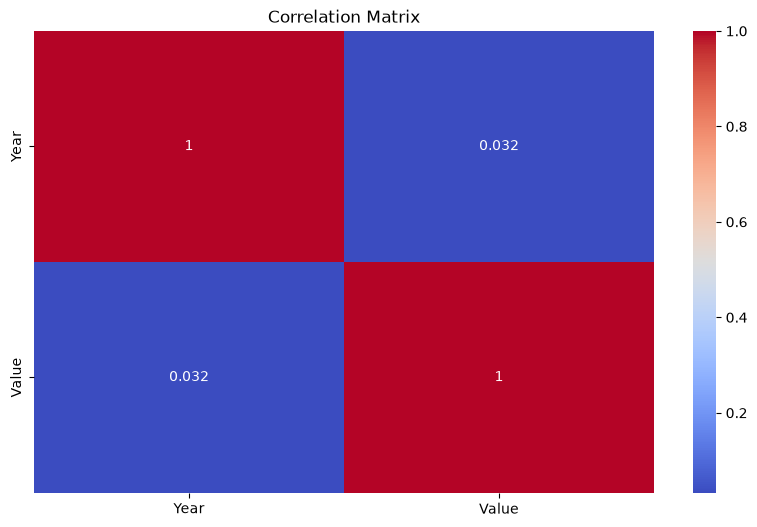

In [5]:
plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()      #Correlation values can fall from -1 to +1, for values I get 0.032 which is weak and positive moderate relationship             

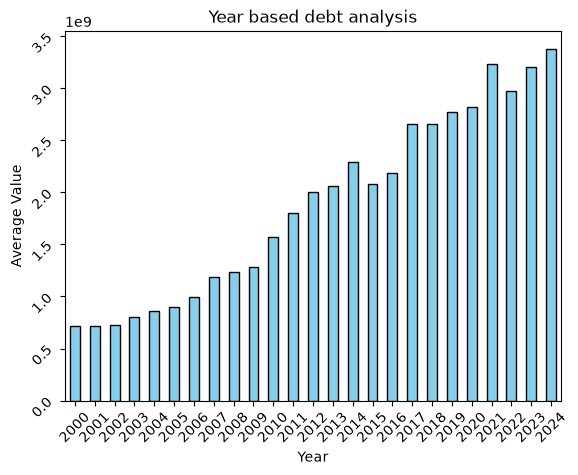

In [6]:
#Country wise debt analysis
year_v=EDA_df.groupby('Year')['Value'].mean()

plt.Figure(figsize=(10, 7))
year_v.plot(kind='bar', color='skyblue', edgecolor='black')


plt.xlabel('Year')
plt.ylabel('Average Value')
plt.title("Year based debt analysis")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()

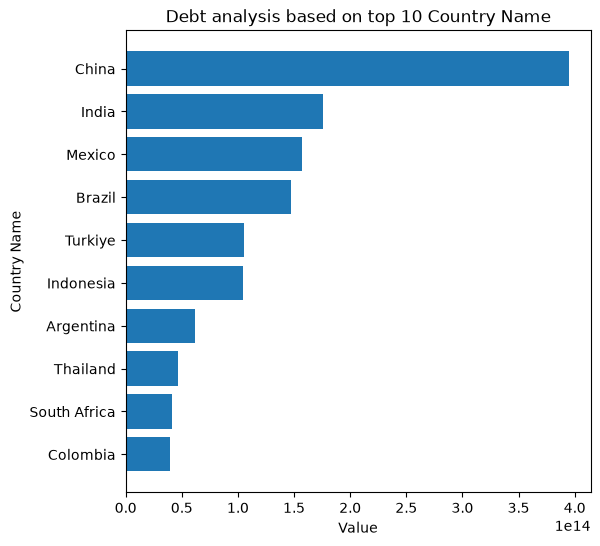

In [7]:
Country_year=(EDA_df.groupby('Country Name')['Value'].sum().nlargest(10))
plt.figure(figsize=(6,6))
plt.barh(Country_year.index, Country_year.values)
plt.xlabel('Value')
plt.ylabel('Country Name')
plt.title("Debt analysis based on top 10 Country Name")
plt.gca().invert_yaxis()
plt.show()

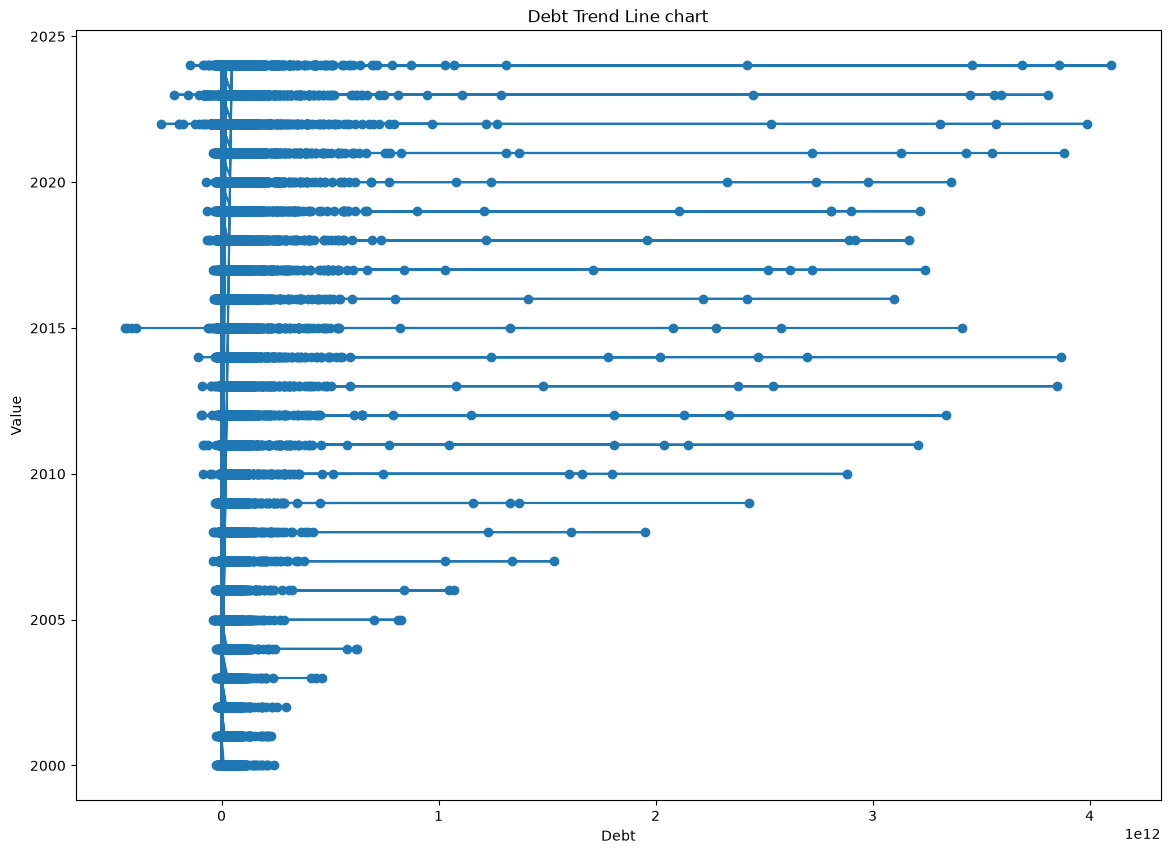

In [8]:
#Debt trend	Line chart
Country_year=(EDA_df.groupby('Year')['Value'].sum().nlargest(10))


plt.figure(figsize=(14,10))


plt.plot(EDA_df['Value'], EDA_df["Year"], marker="o")
plt.title("Debt Trend Line chart")
plt.xlabel("Debt")
plt.ylabel("Value")
plt.show()



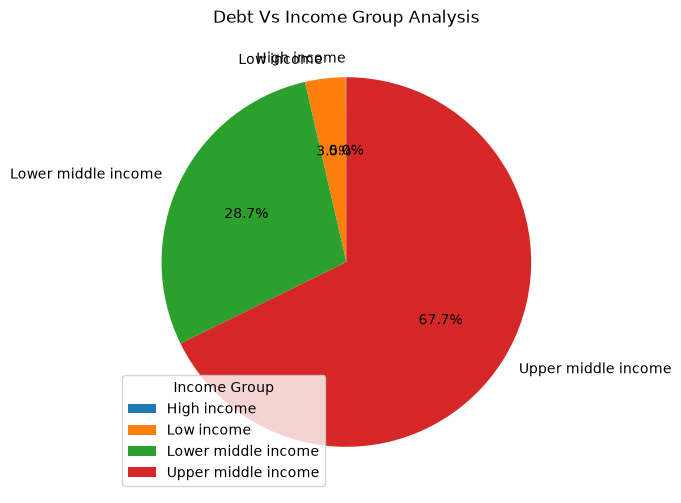

In [19]:
income_ana=EDA_df.groupby("Income Group")['Value'].sum()

plt.figure(figsize=(14,6))
plt.pie(income_ana, labels=income_ana.index, autopct="%1.1f%%", startangle=90)
plt.legend(title="Income Group")        
plt.title("Debt Vs Income Group Analysis")
plt.show()


In [10]:
EDA_df['Region'].unique()

<StringArray>
['Middle East & North Africa',         'Sub-Saharan Africa',
      'Europe & Central Asia',  'Latin America & Caribbean',
                 'South Asia',        'East Asia & Pacific']
Length: 6, dtype: str

In [11]:
EDA_df.groupby('Region')['Value'].median()



Region
East Asia & Pacific           33582790.20
Europe & Central Asia         37064728.95
Latin America & Caribbean     15800141.50
Middle East & North Africa    35817304.40
South Asia                    59090000.00
Sub-Saharan Africa            19000000.00
Name: Value, dtype: float64

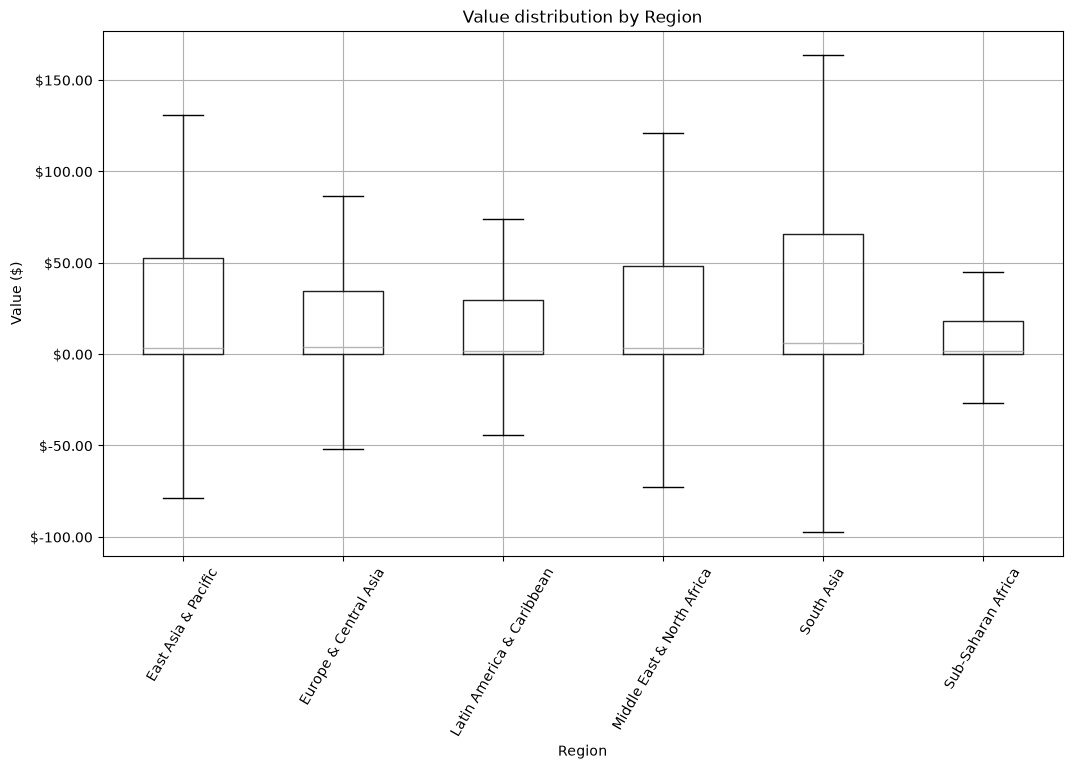

In [12]:
EDA_df.groupby('Region')['Value'].median()

from matplotlib.ticker import FuncFormatter
EDA_df.boxplot(column='Value', by='Region', figsize=(12,7), showfliers=False)


plt.xlabel('Region')
plt.ylabel('Value ($)')
plt.title('Value distribution by Region')
plt.suptitle('')
plt.xticks(rotation=60)
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, pos:f'${x/1e7:.2f}'))
plt.show()


In [13]:
EDA_df.groupby('Lending category')['Year'].agg(lambda x:x.mode().iloc[0])

Lending category
Blend    2002
IBRD     2002
IDA      2019
Name: Year, dtype: int64

In [14]:
EDA_df.groupby("Lending category")['Year'].value_counts()


Lending category  Year
Blend             2002     6816
                  2000     6750
                  2004     6738
                  2003     6719
                  2019     6678
                          ...  
IDA               2024    17177
                  2003    17160
                  2014    17147
                  2007    17107
                  2001    17052
Name: count, Length: 75, dtype: int64

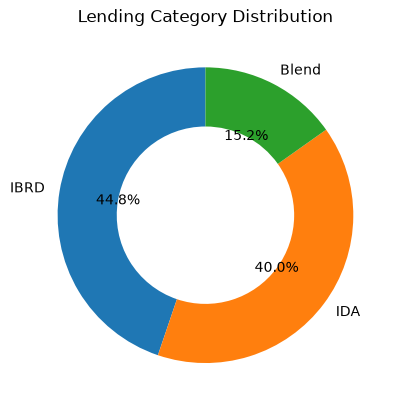

In [15]:
data = EDA_df["Lending category"].value_counts()

plt.pie(
    data.values,
    labels=data.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Lending Category Distribution")
plt.show()

In [16]:
data = EDA_df.groupby("Lending category")["Year"].value_counts()


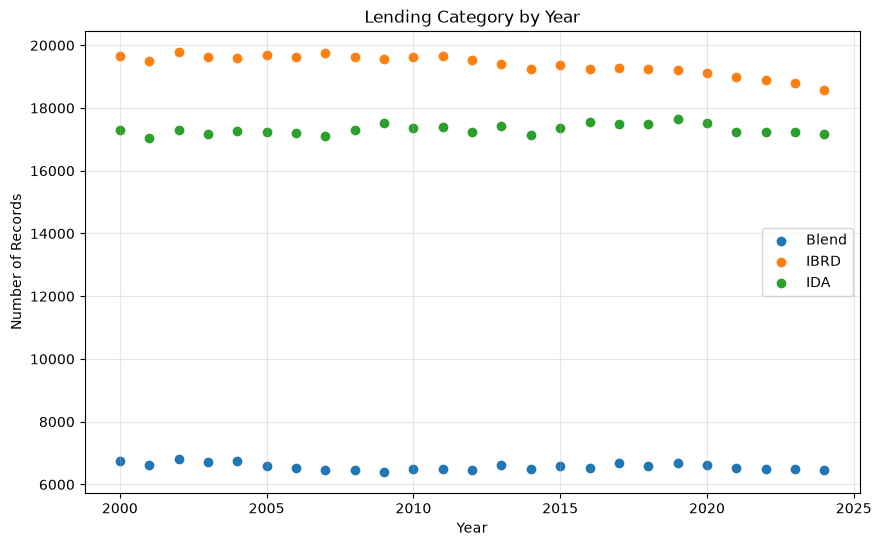

In [17]:
data = data.reset_index()
data.columns = ["Lending category", "Year", "Count"]

plt.figure(figsize=(10, 6))

for category in data["Lending category"].unique():
    subset = data[data["Lending category"] == category]

    plt.scatter(
        subset["Year"],
        subset["Count"],
        label=category
    )

plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.title("Lending Category by Year")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()